In [ ]:
# Install required libraries
!pip install pandas numpy matplotlib seaborn scipy

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Set graph style
sns.set_style("whitegrid")

print("Python environment is ready!")

Python environment is ready!


HOTEL BOOKINGS


Part 1: Loading Data & Basic Inspection (Codes 1–10)
Code 1: Import essential libraries


In [23]:
df = pd.read_csv("hotel_bookings.csv")

In [24]:
print("Dataset shape:", df.shape)

Dataset shape: (119390, 32)


In [25]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [26]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [28]:
df.describe().round(2)

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119390.00,119386.0,119390.00,119390.00,119390.00,119390.00,119390.00,103050.00,6797.00,119390.00,119390.00,119390.00,119390.00
mean,0.37,104.01,2016.16,27.17,15.80,0.93,2.50,1.86,0.1,0.01,0.03,0.09,0.14,0.22,86.69,189.27,2.32,101.83,0.06,0.57
std,0.48,106.86,0.71,13.61,8.78,1.00,1.91,0.58,0.4,0.10,0.18,0.84,1.50,0.65,110.77,131.66,17.59,50.54,0.25,0.79
min,0.00,0.00,2015.00,1.00,1.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,1.00,6.00,0.00,-6.38,0.00,0.00
25%,0.00,18.00,2016.00,16.00,8.00,0.00,1.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,9.00,62.00,0.00,69.29,0.00,0.00
50%,0.00,69.00,2016.00,28.00,16.00,1.00,2.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,14.00,179.00,0.00,94.58,0.00,0.00
75%,1.00,160.00,2017.00,38.00,23.00,2.00,3.00,2.00,0.0,0.00,0.00,0.00,0.00,0.00,229.00,270.00,0.00,126.00,0.00,1.00
max,1.00,737.00,2017.00,53.00,31.00,19.00,50.00,55.00,10.0,10.00,1.00,26.00,72.00,21.00,535.00,543.00,391.00,5400.00,8.00,5.00


In [29]:
df.describe(include="object")

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [30]:
df.describe(include="object")

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [31]:
print("Total cells:", df.size)

Total cells: 3820480


In [32]:
print("Columns:", df.columns.tolist())

Columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


Part 2: Python Data Structures — Lists, Tuples, Sets, Dictionaries

In [33]:
room_types = ["Single", "Double", "Twin", "Suite", "Deluxe", "Executive"]
print("Room Types List:", room_types)

Room Types List: ['Single', 'Double', 'Twin', 'Suite', 'Deluxe', 'Executive']


In [34]:
hotel_info = ("HTL01", "Grand Palace Hotel", "New Delhi")
print("Hotel Tuple:", hotel_info)

Hotel Tuple: ('HTL01', 'Grand Palace Hotel', 'New Delhi')


In [35]:
meal_plans = {"BB", "HB", "FB", "SC", "BB", "HB"}
print("Unique Meal Plans Set:", meal_plans)

Unique Meal Plans Set: {'HB', 'BB', 'FB', 'SC'}


In [36]:
room_tariff = {
    "Single": 3500,
    "Double": 5000,
    "Twin": 5200,
    "Suite": 12000,
    "Deluxe": 7500,
    "Executive": 9500
}
print("Room Tariff Dict:", room_tariff)

Room Tariff Dict: {'Single': 3500, 'Double': 5000, 'Twin': 5200, 'Suite': 12000, 'Deluxe': 7500, 'Executive': 9500}


In [44]:
hotel_list = df["hotel"].tolist()
adr_list = df["adr"].tolist()
lead_time_list = df["lead_time"].tolist()
country_list = df["country"].dropna().tolist()

In [45]:
unique_countries = set(country_list)
unique_segments = set(df["market_segment"].tolist())
print("Total Unique Countries:", len(unique_countries))
print("Market Segments:", unique_segments)

Total Unique Countries: 177
Market Segments: {'Offline TA/TO', 'Direct', 'Corporate', 'Aviation', 'Complementary', 'Groups', 'Online TA', 'Undefined'}


In [46]:
first_booking = df.iloc[0].to_dict()
print("First Booking Record:", first_booking)

First Booking Record: {'hotel': 'Resort Hotel', 'is_canceled': 0, 'lead_time': 342, 'arrival_date_year': 2015, 'arrival_date_month': 'July', 'arrival_date_week_number': 27, 'arrival_date_day_of_month': 1, 'stays_in_weekend_nights': 0, 'stays_in_week_nights': 0, 'adults': 2, 'children': 0.0, 'babies': 0, 'meal': 'BB', 'country': 'PRT', 'market_segment': 'Direct', 'distribution_channel': 'Direct', 'is_repeated_guest': 0, 'previous_cancellations': 0, 'previous_bookings_not_canceled': 0, 'reserved_room_type': 'C', 'assigned_room_type': 'C', 'booking_changes': 3, 'deposit_type': 'No Deposit', 'agent': nan, 'company': nan, 'days_in_waiting_list': 0, 'customer_type': 'Transient', 'adr': 0.0, 'required_car_parking_spaces': 0, 'total_of_special_requests': 0, 'reservation_status': 'Check-Out', 'reservation_status_date': '2015-07-01'}


In [47]:
first_5_bookings = df.head(5).to_dict("records")
print("3rd Booking Hotel:", first_5_bookings[2]["hotel"])

3rd Booking Hotel: Resort Hotel


In [48]:
print("First room:", room_types[0])
print("Last room:", room_types[-1])
print("First three rooms:", room_types[0:3])
print("Every 2nd room:", room_types[::2])

First room: Single
Last room: Executive
First three rooms: ['Single', 'Double', 'Twin']
Every 2nd room: ['Single', 'Twin', 'Deluxe']


In [49]:
print("Suite Price:", room_tariff.get("Suite"))
print("Penthouse Price:", room_tariff.get("Penthouse", "Room type not available"))

Suite Price: 12000
Penthouse Price: Room type not available


In [50]:
print("Is IND in countries?", "IND" in unique_countries)
print("Is USA in countries?", "USA" in unique_countries)

Is IND in countries? True
Is USA in countries? True


In [51]:
room_types.append("Presidential")
room_types.remove("Presidential")
try:
    hotel_info[2] = "Mumbai"
except TypeError as e:
    print("Tuple Error:", e)

Tuple Error: 'tuple' object does not support item assignment


In [52]:
clean_adr = [x for x in adr_list if pd.notnull(x) and x > 0]
print("Total valid bookings:", len(clean_adr))
print("Average ADR:", round(sum(clean_adr) / len(clean_adr), 2))
print("Highest ADR:", max(clean_adr))
print("Lowest ADR:", min(clean_adr))
print("Top 5 ADRs:", sorted(clean_adr, reverse=True)[:5])

Total valid bookings: 117430
Average ADR: 103.53
Highest ADR: 5400.0
Lowest ADR: 0.26
Top 5 ADRs: [5400.0, 510.0, 508.0, 451.5, 450.0]


In [53]:
bookings_per_hotel = {}
for h in hotel_list:
    bookings_per_hotel[h] = bookings_per_hotel.get(h, 0) + 1
print("Bookings per hotel:", bookings_per_hotel)

Bookings per hotel: {'Resort Hotel': 40060, 'City Hotel': 79330}


In [54]:
most_booked_hotel = max(bookings_per_hotel, key=bookings_per_hotel.get)
print("Most booked hotel type:", most_booked_hotel)

Most booked hotel type: City Hotel


In [55]:
segment_list = df["market_segment"].tolist()
revenue_by_segment = {}
for seg, rate in zip(segment_list, adr_list):
    if pd.notnull(rate):
        revenue_by_segment[seg] = round(revenue_by_segment.get(seg, 0) + rate, 2)
print("Total ADR by Segment:", revenue_by_segment)

Total ADR by Segment: {'Direct': 1455301.88, 'Corporate': 367255.65, 'Online TA': 6618938.52, 'Offline TA/TO': 2115645.48, 'Complementary': 2144.57, 'Groups': 1574567.82, 'Undefined': 30.0, 'Aviation': 23733.68}


In [56]:
luxury_bookings = [r for r in clean_adr if r > 200]
print("Count of bookings with ADR > 200:", len(luxury_bookings))

Count of bookings with ADR > 200: 4929


In [57]:
last_minute = [lt for lt in lead_time_list if lt <= 3]
print("Last-minute bookings count:", len(last_minute))

Last-minute bookings count: 13690


In [58]:
discounted_tariff = {room: round(price * 0.90, 2) for room, price in room_tariff.items()}
print("Discounted Tariffs:", discounted_tariff)

Discounted Tariffs: {'Single': 3150.0, 'Double': 4500.0, 'Twin': 4680.0, 'Suite': 10800.0, 'Deluxe': 6750.0, 'Executive': 8550.0}


In [59]:
resort_countries = set(df[df["hotel"] == "Resort Hotel"]["country"].dropna())
city_countries = set(df[df["hotel"] == "City Hotel"]["country"].dropna())
print("Countries in BOTH hotels:", len(resort_countries & city_countries))
print("Countries ONLY in Resort Hotel:", len(resort_countries - city_countries))

Countries in BOTH hotels: 114
Countries ONLY in Resort Hotel: 11


Part 3: NumPy Operations & Pandas Data Manipulation


In [60]:
adr_arr = df["adr"].to_numpy()
lead_arr = df["lead_time"].to_numpy()

In [61]:
print("NumPy Mean Lead Time:", np.nanmean(lead_arr).round(2))
print("NumPy Median Lead Time:", np.nanmedian(lead_arr))
print("NumPy Std Dev Lead Time:", np.nanstd(lead_arr).round(2))

NumPy Mean Lead Time: 104.01
NumPy Median Lead Time: 69.0
NumPy Std Dev Lead Time: 106.86


In [62]:
print("ADR Percentiles:", np.nanpercentile(adr_arr, [25, 50, 75, 95]))

ADR Percentiles: [ 69.29   94.575 126.    193.5  ]


In [65]:
df["total_revenue"] = df["adr"] * df["total_nights"]

In [66]:
df["room_changed"] = df["reserved_room_type"] != df["assigned_room_type"]
print("Room change counts:\n", df["room_changed"].value_counts())

Room change counts:
 room_changed
False    104473
True      14917
Name: count, dtype: int64


In [67]:
print("Cancellation Counts:\n", df["is_canceled"].value_counts())

Cancellation Counts:
 is_canceled
0    75166
1    44224
Name: count, dtype: int64


In [68]:
print("Deposit Type %:\n", (df["deposit_type"].value_counts(normalize=True) * 100).round(2))

Deposit Type %:
 deposit_type
No Deposit    87.65
Non Refund    12.22
Refundable     0.14
Name: proportion, dtype: float64


In [69]:
city_confirmed = df.loc[(df["hotel"] == "City Hotel") & (df["is_canceled"] == 0)]
print("Confirmed City Hotel bookings:", len(city_confirmed))

Confirmed City Hotel bookings: 46228


In [70]:
subset_iloc = df.iloc[10:21, 0:6]
print(subset_iloc)

           hotel  is_canceled  lead_time  arrival_date_year  \
10  Resort Hotel            1         23               2015   
11  Resort Hotel            0         35               2015   
12  Resort Hotel            0         68               2015   
13  Resort Hotel            0         18               2015   
14  Resort Hotel            0         37               2015   
15  Resort Hotel            0         68               2015   
16  Resort Hotel            0         37               2015   
17  Resort Hotel            0         12               2015   
18  Resort Hotel            0          0               2015   
19  Resort Hotel            0          7               2015   
20  Resort Hotel            0         37               2015   

   arrival_date_month  arrival_date_week_number  
10               July                        27  
11               July                        27  
12               July                        27  
13               July                      

In [71]:
vip_bookings = df[(df["total_of_special_requests"] >= 3) & (df["adr"] > 150)]
print("VIP Bookings count:", len(vip_bookings))

VIP Bookings count: 792


In [72]:
print(df.groupby("hotel")[["adr", "lead_time", "total_nights"]].mean().round(2))

                 adr  lead_time  total_nights
hotel                                        
City Hotel    105.30     109.74          2.98
Resort Hotel   94.95      92.68          4.32


In [73]:
cancel_by_segment = (df.groupby("market_segment")["is_canceled"].mean() * 100).round(2)
print("Cancellation Rate (%) by Segment:\n", cancel_by_segment.sort_values(ascending=False))

Cancellation Rate (%) by Segment:
 market_segment
Undefined        100.00
Groups            61.06
Online TA         36.72
Offline TA/TO     34.32
Aviation          21.94
Corporate         18.73
Direct            15.34
Complementary     13.06
Name: is_canceled, dtype: float64


In [74]:
yearly_summary = df.groupby("arrival_date_year").agg(
    Total_Bookings=("hotel", "count"),
    Total_Revenue=("total_revenue", "sum"),
    Avg_ADR=("adr", "mean")
).round(2)
print(yearly_summary)

                   Total_Bookings  Total_Revenue  Avg_ADR
arrival_date_year                                        
2015                        21996     6818116.56    87.18
2016                        56707    18870601.20    98.33
2017                        40687    17034779.77   114.64


In [75]:
print((df.groupby("deposit_type")["is_canceled"].mean() * 100).round(2))

deposit_type
No Deposit    28.38
Non Refund    99.36
Refundable    22.22
Name: is_canceled, dtype: float64


In [76]:
pivot_adr = pd.pivot_table(df, values="adr", index="hotel", columns="customer_type", aggfunc="mean").round(2)
print(pivot_adr)

customer_type  Contract  Group  Transient  Transient-Party
hotel                                                     
City Hotel        94.05  91.95     110.02            90.87
Resort Hotel      79.12  74.76     101.11            75.43


In [77]:
ct_status = pd.crosstab(df["hotel"], df["reservation_status"])
print(ct_status)

reservation_status  Canceled  Check-Out  No-Show
hotel                                           
City Hotel             32186      46228      916
Resort Hotel           10831      28938      291


In [78]:
top_10_countries = df["country"].value_counts().head(10)
print("Top 10 Countries:\n", top_10_countries)

Top 10 Countries:
 country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64


In [79]:
top_5_rev = df.sort_values(by="total_revenue", ascending=False)[["hotel", "country", "total_nights", "adr", "total_revenue"]].head(5)
print(top_5_rev)

              hotel country  total_nights     adr  total_revenue
14038  Resort Hotel     NaN            69   110.0         7590.0
14037  Resort Hotel     NaN            60   110.5         6630.0
13142  Resort Hotel     PRT            14   450.0         6300.0
60133    City Hotel     AGO            29   212.0         6148.0
48515    City Hotel     PRT             1  5400.0         5400.0


In [80]:
df["lead_time_category"] = pd.cut(
    df["lead_time"],
    bins=[-1, 7, 30, 90, 1000],
    labels=["Last Minute (0-7d)", "Short Term (8-30d)", "Medium Term (31-90d)", "Advance (>90d)"]
)
print(df["lead_time_category"].value_counts())

lead_time_category
Advance (>90d)          51131
Medium Term (31-90d)    29553
Last Minute (0-7d)      19746
Short Term (8-30d)      18960
Name: count, dtype: int64


In [82]:
monthly_bookings = df.groupby(["arrival_month_num", "arrival_date_month"]).size()
print(monthly_bookings)

arrival_month_num  arrival_date_month
1                  January                5929
2                  February               8068
3                  March                  9794
4                  April                 11089
5                  May                   11791
6                  June                  10939
7                  July                  12661
8                  August                13877
9                  September             10508
10                 October               11160
11                 November               6794
12                 December               6780
dtype: int64


In [83]:
print((df.groupby("is_repeated_guest")["is_canceled"].mean() * 100).round(2))


is_repeated_guest
0    37.79
1    14.49
Name: is_canceled, dtype: float64


In [84]:
num_cols = ["lead_time", "total_nights", "total_guests", "previous_cancellations", "booking_changes", "adr", "total_of_special_requests"]
corr_matrix = df[num_cols].corr().round(2)
print(corr_matrix)

                           lead_time  total_nights  total_guests  \
lead_time                       1.00          0.16          0.07   
total_nights                    0.16          1.00          0.12   
total_guests                    0.07          0.12          1.00   
previous_cancellations          0.09         -0.02         -0.02   
booking_changes                 0.00          0.10         -0.00   
adr                            -0.06          0.07          0.37   
total_of_special_requests      -0.10          0.08          0.16   

                           previous_cancellations  booking_changes   adr  \
lead_time                                    0.09             0.00 -0.06   
total_nights                                -0.02             0.10  0.07   
total_guests                                -0.02            -0.00  0.37   
previous_cancellations                       1.00            -0.03 -0.07   
booking_changes                             -0.03             1.00  0.02   

Part 4: Data Cleaning, Missing Values & Anomaly Detection

In [85]:
print("Missing values per column:\n", df.isnull().sum()[df.isnull().sum() > 0])

Missing values per column:
 children         4
country        488
agent        16340
company     112593
dtype: int64


In [86]:
total_blank = df.isnull().sum().sum()
print("Total Blank Cells:", total_blank)
print("Blank %:", round((total_blank / df.size) * 100, 2), "%")

Total Blank Cells: 129425
Blank %: 2.85 %


In [87]:
rows_with_null = df.isnull().any(axis=1).sum()
print(f"Rows with at least one blank: {rows_with_null} out of {len(df)}")

Rows with at least one blank: 119173 out of 119390


In [88]:
duplicates = df.duplicated().sum()
print("Exact duplicate rows:", duplicates)

Exact duplicate rows: 31994


In [89]:
check_cols = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "adr", "days_in_waiting_list"]
gap = pd.DataFrame({
    "Mean": df[check_cols].mean(),
    "Median": df[check_cols].median()
})
gap["Gap %"] = ((gap["Mean"] - gap["Median"]) / gap["Median"].replace(0, np.nan) * 100).round(1)
print(gap.round(2))

                           Mean  Median  Gap %
lead_time                104.01   69.00   50.7
stays_in_weekend_nights    0.93    1.00   -7.2
stays_in_week_nights       2.50    2.00   25.0
adults                     1.86    2.00   -7.2
adr                      101.83   94.58    7.7
days_in_waiting_list       2.32    0.00    NaN


In [91]:
for col, (low, high) in rules.items():
    bad = df[(df[col] < low) | (df[col] > high)]
    print(f"{col} -> impossible/anomalous values: {len(bad)}")

adr -> impossible/anomalous values: 2
adults -> impossible/anomalous values: 415
lead_time -> impossible/anomalous values: 1
total_nights -> impossible/anomalous values: 716


In [92]:
invalid_adr = df[df["adr"] <= 0]
print("Bookings with ADR <= 0:", len(invalid_adr))

Bookings with ADR <= 0: 1960


In [93]:
zero_guests = df[df["total_guests"] == 0]
print("Bookings with 0 total guests:", len(zero_guests))

Bookings with 0 total guests: 180


In [94]:
zero_nights = df[df["total_nights"] == 0]
print("Bookings with 0 nights stayed:", len(zero_nights))

Bookings with 0 nights stayed: 715


Graph 1: Missing Values Heatmap (Raw Data Check)

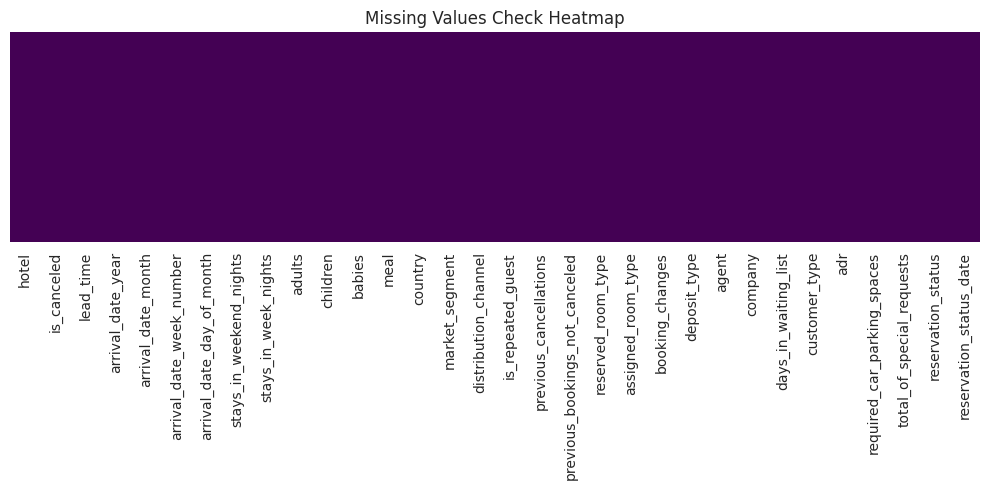

In [98]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Check Heatmap")
plt.tight_layout()
plt.show()

Graph 2: Multi-Boxplots (Outlier Detection for Top Numeric Columns)

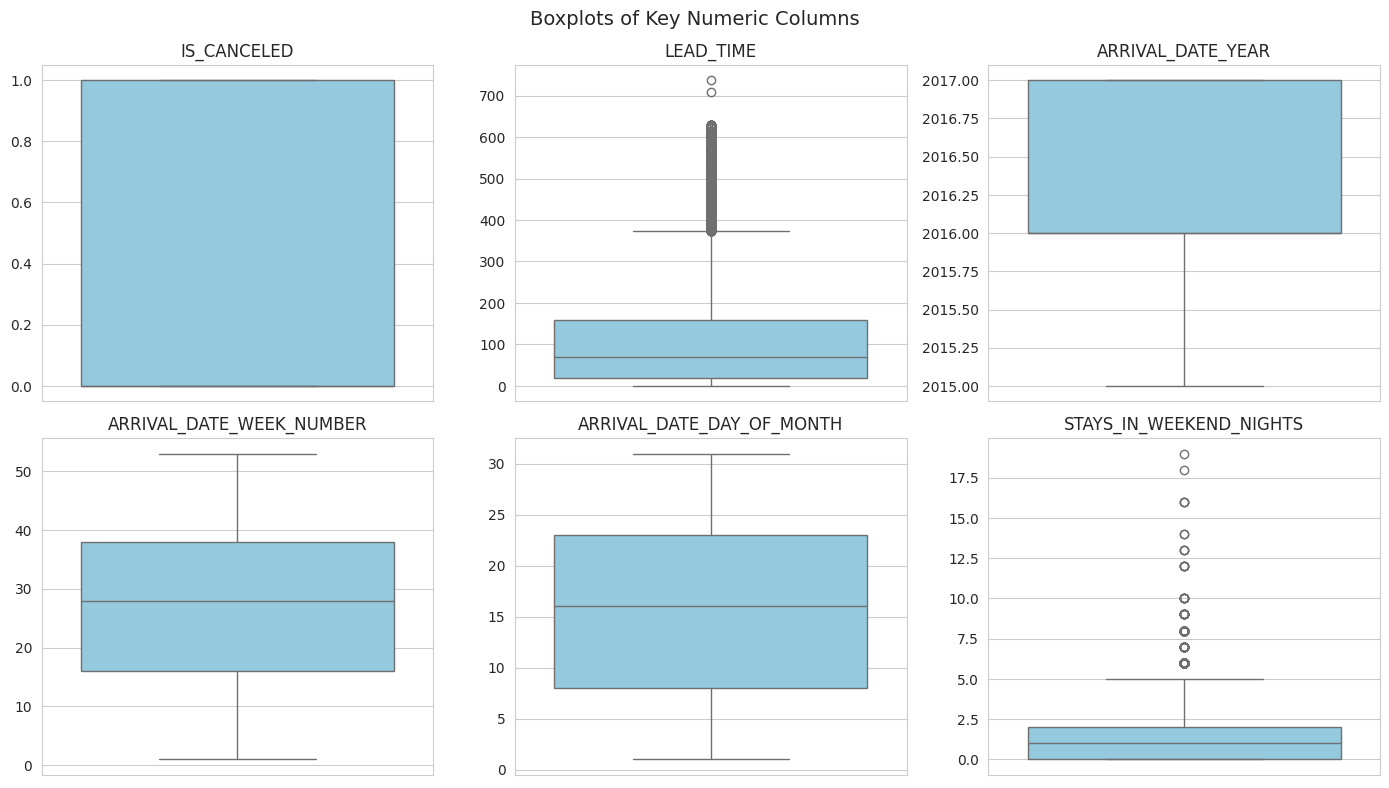

In [99]:
num_cols = df.select_dtypes(include=[np.number]).columns[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col.upper())
    axes[i].set_ylabel("")
plt.suptitle("Boxplots of Key Numeric Columns", fontsize=14)
plt.tight_layout()
plt.show()

Graph 3: Bar Chart — First Categorical Column Count (e.g., Hotel Type)

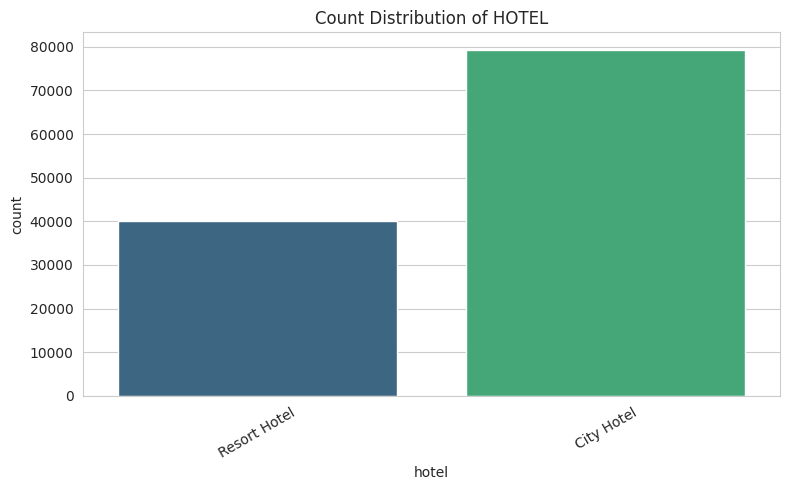

In [100]:
cat_col = df.select_dtypes(include=["object"]).columns[0]
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x=cat_col, palette="viridis")
plt.title(f"Count Distribution of {cat_col.upper()}")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Graph 4: Pie Chart — Proportion of Top Categories

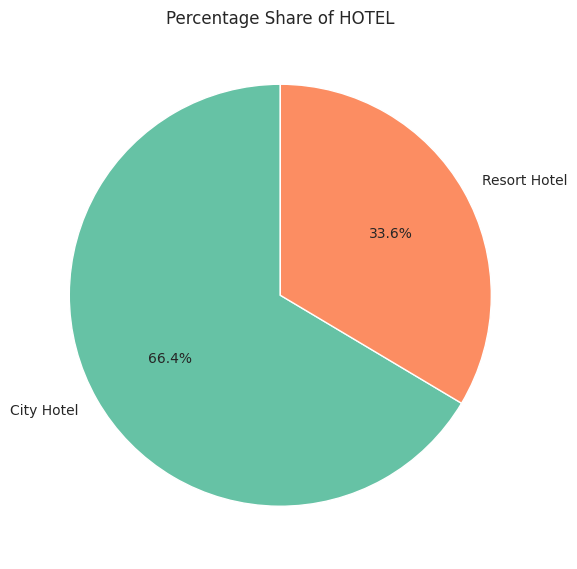

In [101]:
cat_col = df.select_dtypes(include=["object"]).columns[0]
counts = df[cat_col].value_counts().head(5)
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
plt.title(f"Percentage Share of {cat_col.upper()}")
plt.tight_layout()
plt.show()

Graph 5: Donut Chart — Market Segment / Second Category Share

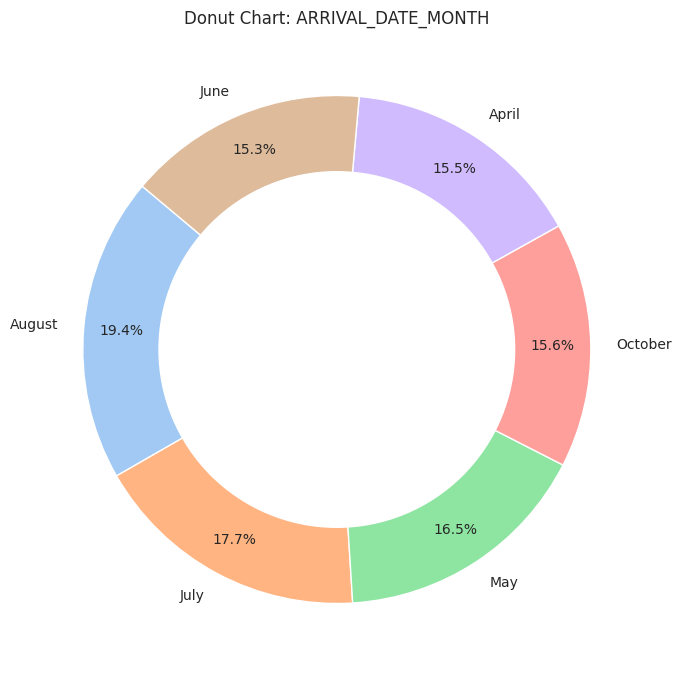

In [102]:
cat_cols = df.select_dtypes(include=["object"]).columns
col_to_plot = cat_cols[1] if len(cat_cols) > 1 else cat_cols[0]
counts = df[col_to_plot].value_counts().head(6)

plt.figure(figsize=(7, 7))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=140, pctdistance=0.85, colors=sns.color_palette("pastel"))
plt.gca().add_artist(plt.Circle((0, 0), 0.70, fc="white"))
plt.title(f"Donut Chart: {col_to_plot.upper()}")
plt.tight_layout()
plt.show()

Graph 6: Horizontal Bar Chart — Top 10 Frequent Values (e.g., Country)

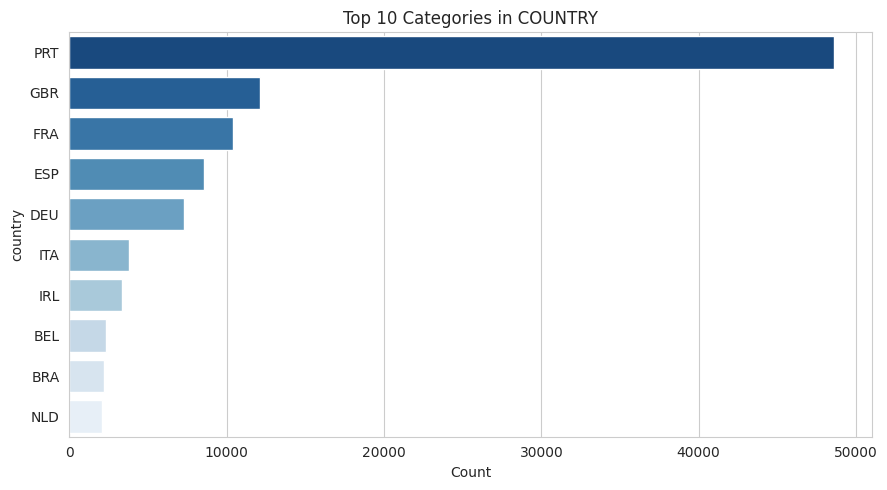

In [103]:
cat_cols = df.select_dtypes(include=["object"]).columns
col_to_plot = "country" if "country" in df.columns else cat_cols[-1]
top_10 = df[col_to_plot].value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_10.values, y=top_10.index, palette="Blues_r")
plt.title(f"Top 10 Categories in {col_to_plot.upper()}")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

Graph 7: Histogram with KDE Curve — Numeric Distribution (e.g., Lead Time / ADR)

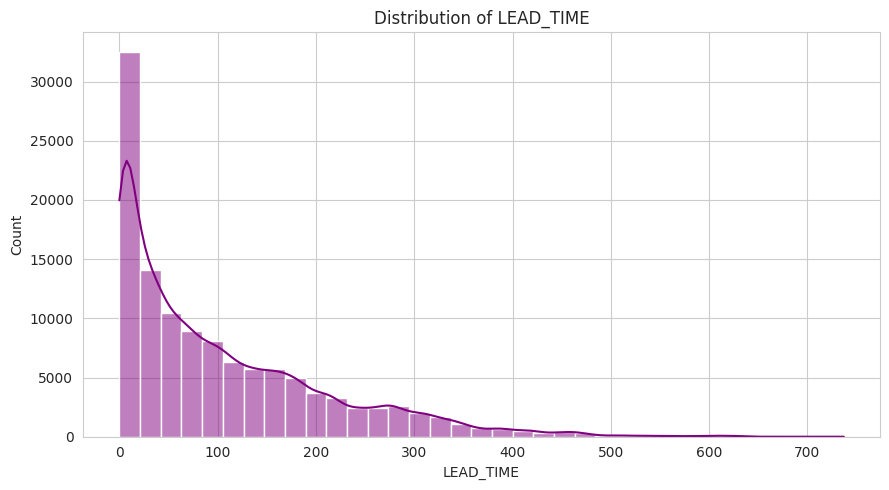

In [105]:
num_col = "lead_time" if "lead_time" in df.columns else df.select_dtypes(include=[np.number]).columns[0]
plt.figure(figsize=(9, 5))
sns.histplot(df[num_col], bins=35, kde=True, color="purple")
plt.title(f"Distribution of {num_col.upper()}")
plt.xlabel(num_col.upper())
plt.tight_layout()
plt.show()

Graph 8: KDE Density Plot — Comparing Two Groups

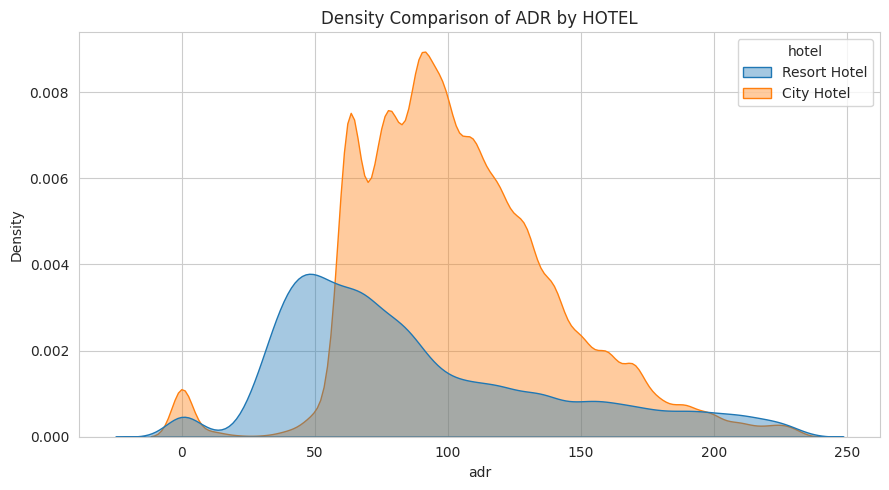

In [106]:
num_col = "adr" if "adr" in df.columns else df.select_dtypes(include=[np.number]).columns[-1]
cat_col = df.select_dtypes(include=["object"]).columns[0]
upper_limit = df[num_col].quantile(0.98)

plt.figure(figsize=(9, 5))
sns.kdeplot(data=df[df[num_col] <= upper_limit], x=num_col, hue=cat_col, fill=True, alpha=0.4)
plt.title(f"Density Comparison of {num_col.upper()} by {cat_col.upper()}")
plt.tight_layout()
plt.show()

Graph 9: Clustered Bar Chart — Comparing Two Categorical Columns

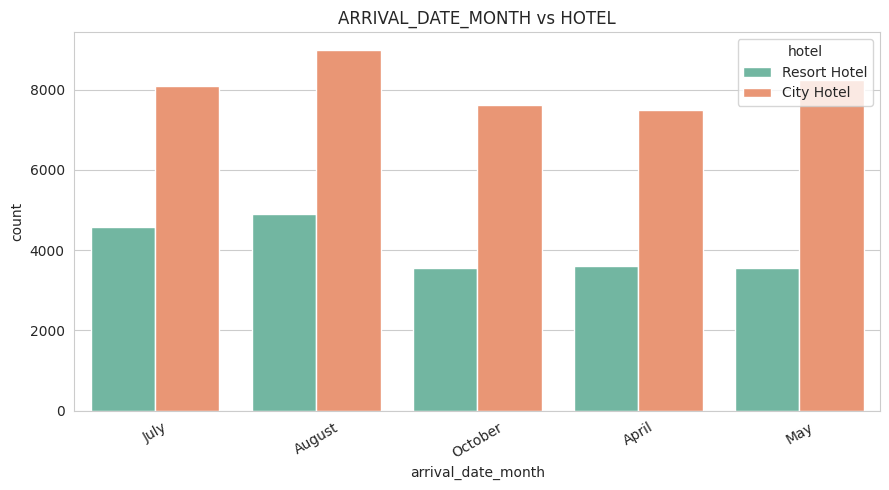

In [107]:
cat_cols = df.select_dtypes(include=["object"]).columns
c1 = cat_cols[0]
c2 = cat_cols[1] if len(cat_cols) > 1 else cat_cols[0]
top_c2 = df[c2].value_counts().head(5).index

plt.figure(figsize=(9, 5))
sns.countplot(data=df[df[c2].isin(top_c2)], x=c2, hue=c1, palette="Set2")
plt.title(f"{c2.upper()} vs {c1.upper()}")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Graph 10: 100% Stacked Bar Chart — Category Proportions

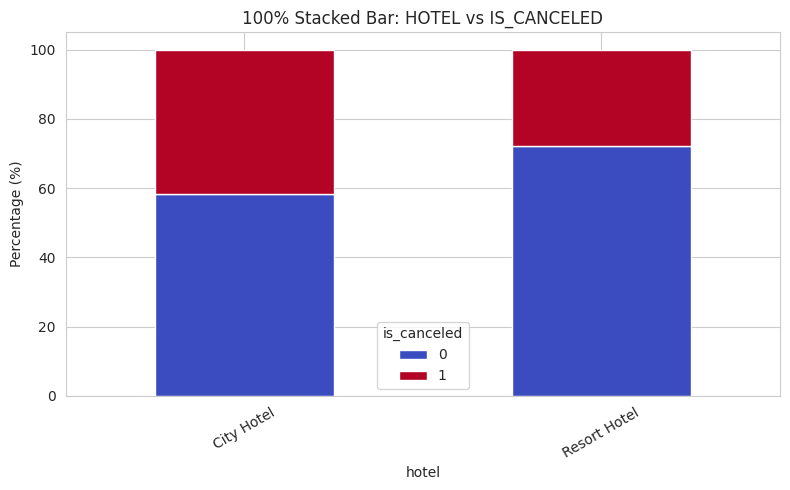

In [108]:
cat_cols = df.select_dtypes(include=["object"]).columns
c1 = cat_cols[0]
c2 = "is_canceled" if "is_canceled" in df.columns else (cat_cols[1] if len(cat_cols) > 1 else cat_cols[0])

ct = pd.crosstab(df[c1], df[c2], normalize="index") * 100
ct.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="coolwarm")
plt.title(f"100% Stacked Bar: {c1.upper()} vs {c2.upper()}")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Graph 11: Violin Plot — Category vs Numeric Spread

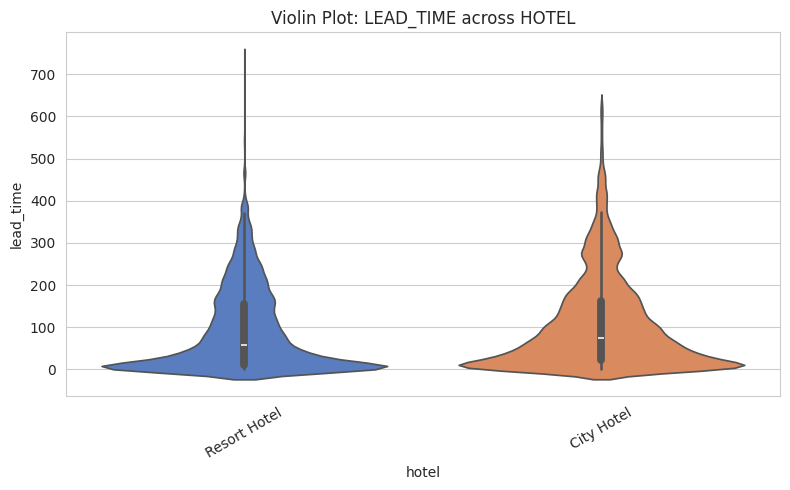

In [109]:
cat_col = df.select_dtypes(include=["object"]).columns[0]
num_col = "lead_time" if "lead_time" in df.columns else df.select_dtypes(include=[np.number]).columns[0]

plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x=cat_col, y=num_col, palette="muted")
plt.title(f"Violin Plot: {num_col.upper()} across {cat_col.upper()}")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Graph 12: Scatter Plot — Relationship Between Two Numeric Variables

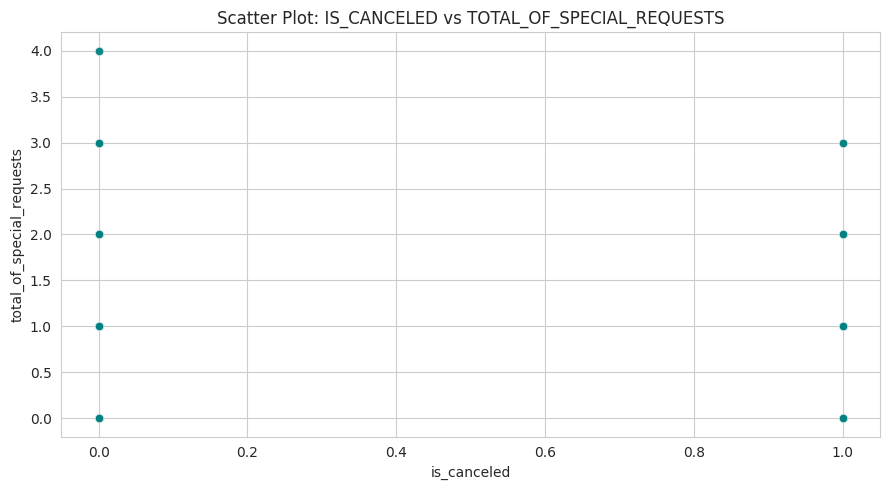

In [110]:
num_cols = df.select_dtypes(include=[np.number]).columns
x_col = num_cols[0]
y_col = num_cols[-1] if len(num_cols) > 1 else num_cols[0]
sample_df = df.sample(min(1500, len(df)), random_state=42)

plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample_df, x=x_col, y=y_col, alpha=0.6, color="teal")
plt.title(f"Scatter Plot: {x_col.upper()} vs {y_col.upper()}")
plt.tight_layout()
plt.show()

Graph 13: Regression Line Plot (regplot) — Trend Analysis

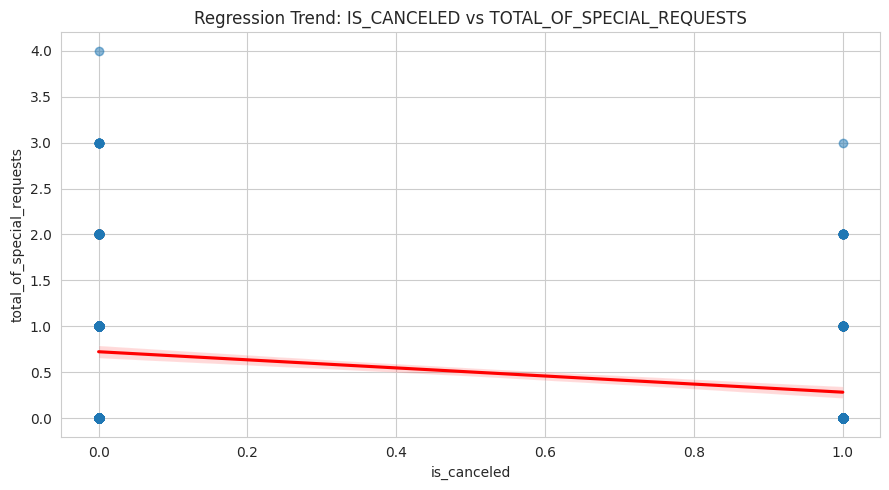

In [111]:
num_cols = df.select_dtypes(include=[np.number]).columns
x_col = num_cols[0]
y_col = num_cols[-1] if len(num_cols) > 1 else num_cols[0]
sample_df = df.sample(min(1000, len(df)), random_state=42)

plt.figure(figsize=(9, 5))
sns.regplot(data=sample_df, x=x_col, y=y_col, scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title(f"Regression Trend: {x_col.upper()} vs {y_col.upper()}")
plt.tight_layout()
plt.show()

Graph 14: ECDF Plot — Cumulative Distribution

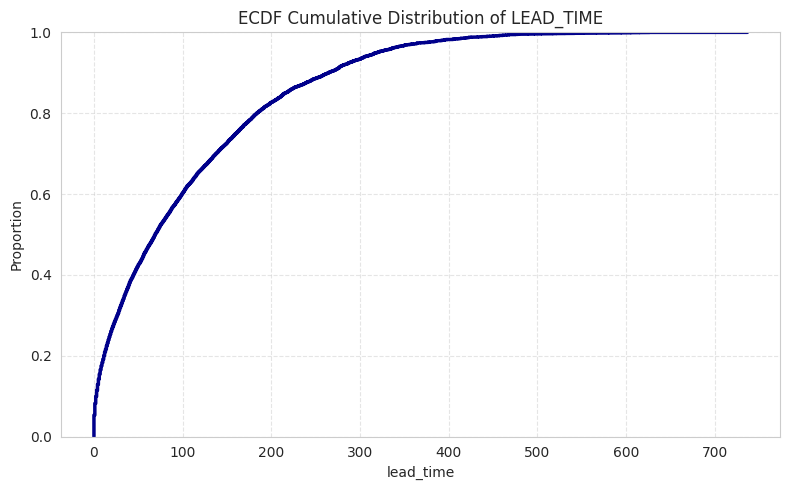

In [112]:
num_col = "lead_time" if "lead_time" in df.columns else df.select_dtypes(include=[np.number]).columns[0]
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x=num_col, linewidth=2.5, color="darkblue")
plt.title(f"ECDF Cumulative Distribution of {num_col.upper()}")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Graph 15: Correlation Heatmap of All Numeric Columns

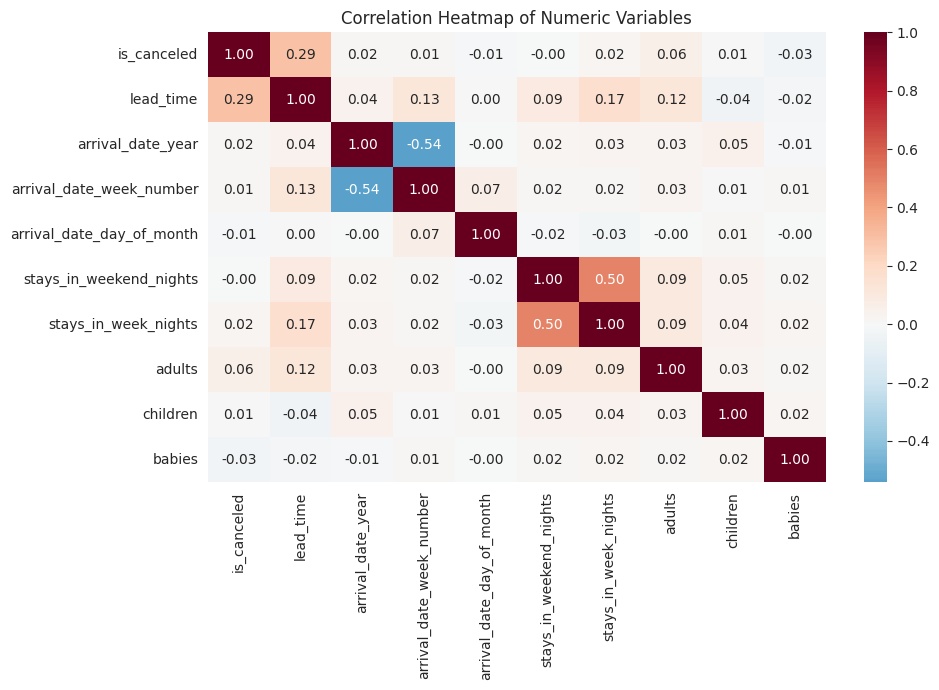

In [113]:
num_df = df.select_dtypes(include=[np.number]).iloc[:, :10]
plt.figure(figsize=(10, 7))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

In [114]:
from google.colab import files

df.to_csv("cleaned_hotel_bookings.csv", index=False)
files.download("cleaned_hotel_bookings.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>